# Training Different Classifiers on the YesNo Dataset
### Speech Processing Assignment

**Student name:** Ali hussien alrekabi &nbsp;&nbsp;&nbsp;&nbsp; **ID:** 404131078

---

## 1. Introduction
The aim of this part of the assignment is to train several classifiers on the YesNo dataset provided by torchaudio and compare their performance. The work was done in Google Colab on CPU using PyTorch 2.14, torchaudio 2.11, scikit-learn, NumPy and Matplotlib. The audio files were loaded with the soundfile library because newer torchaudio versions rely on TorchCodec for loading audio.

## 2. Dataset
The YesNo dataset contains 60 recordings of a single speaker. Each recording is about 6.35 seconds long, sampled at 8 kHz, and contains 8 Hebrew words. Every word is either "ken" (yes) or "lo" (no). The labels are written in the file name as a sequence of 8 digits, where 1 means yes and 0 means no. For example, the file 0_0_0_0_1_1_1_1.wav contains four "no" words followed by four "yes" words.

Since each file has 8 labels and not one, the recordings cannot be classified directly. Each recording has to be cut into its 8 words first, so that every word becomes one sample with one label. This gives at most 60 × 8 = 480 samples.

In [1]:
import torch, torchaudio, os, glob

# Check library versions
print("torch:", torch.__version__, "| torchaudio:", torchaudio.__version__)

# Download the YesNo dataset
os.makedirs("data", exist_ok=True)
torchaudio.datasets.YESNO("data", download=True)

# List all audio files
files = sorted(glob.glob("data/**/*.wav", recursive=True))
print("Number of files:", len(files))
print("First file:", files[0])

# The label is in the filename: 8 digits (0 = no, 1 = yes)
name = os.path.basename(files[0])[:-4]
labels = [int(c) for c in name.split("_")]
print("Labels of first file:", labels)

torch: 2.14.1+cpu | torchaudio: 2.11.0+cpu


100%|██████████| 4.49M/4.49M [00:02<00:00, 1.69MB/s]

Number of files: 60
First file: data/waves_yesno/0_0_0_0_1_1_1_1.wav
Labels of first file: [0, 0, 0, 0, 1, 1, 1, 1]


Sample rate: 8000
Number of samples: 50800
Duration (seconds): 6.35


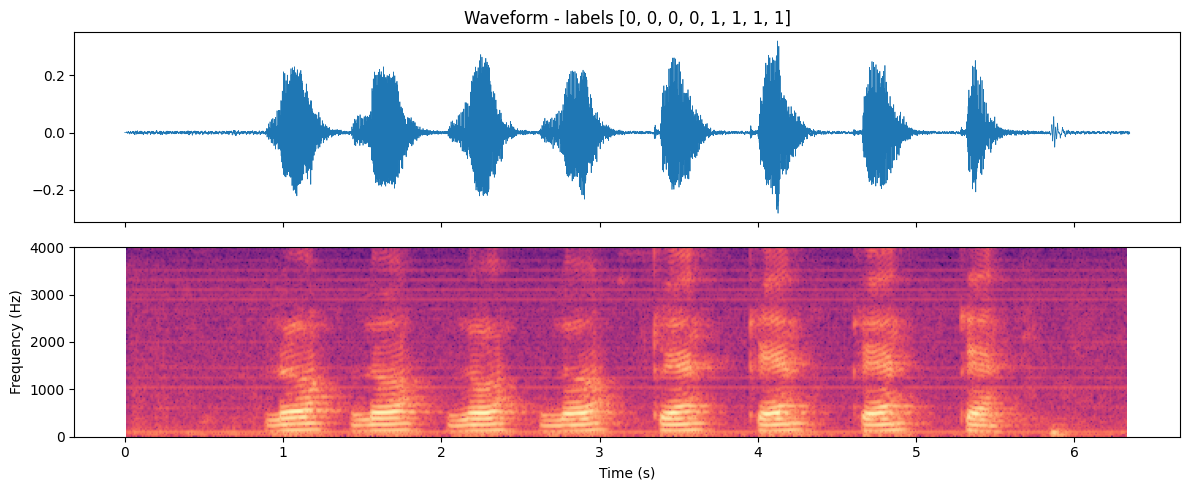

In [2]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt

# Load the first file
x, sr = sf.read(files[0], dtype="float32")
print("Sample rate:", sr)
print("Number of samples:", len(x))
print("Duration (seconds):", len(x) / sr)

# Plot waveform and spectrogram
t = np.arange(len(x)) / sr
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax[0].plot(t, x, linewidth=0.5)
ax[0].set_title(f"Waveform - labels {labels}")
ax[1].specgram(x, Fs=sr, NFFT=256, noverlap=176, cmap="magma")
ax[1].set_ylabel("Frequency (Hz)")
ax[1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

# Listen to it
from IPython.display import Audio
Audio(x, rate=sr)

*Figure 1: Waveform and spectrogram of the first recording. The 8 words appear as separate bursts of energy.*

## 3. Method
### 3.1 Word segmentation
The words were separated using an energy-based method. The signal was divided into frames of 25 ms (200 samples) with a hop of 10 ms (80 samples), and the energy of each frame was calculated in dB. Frames with energy above a threshold were considered speech. Gaps shorter than 150 ms were merged so that a word is not split into two parts, and segments shorter than 100 ms were removed to ignore short noises. A padding of 50 ms was added to each side of every word.

In the first attempt the threshold was set between the noise floor and the speech peak. This threshold was too low: the first two words of a recording were merged into one segment and a small click at the end of the recording was detected as a word. The number of segments was still 8, so the error could only be seen by plotting the result. The threshold was then changed to be 15 dB below the peak energy of the recording. If exactly 8 words were not found, other values between 8 and 25 dB were tried.

Found 8 words


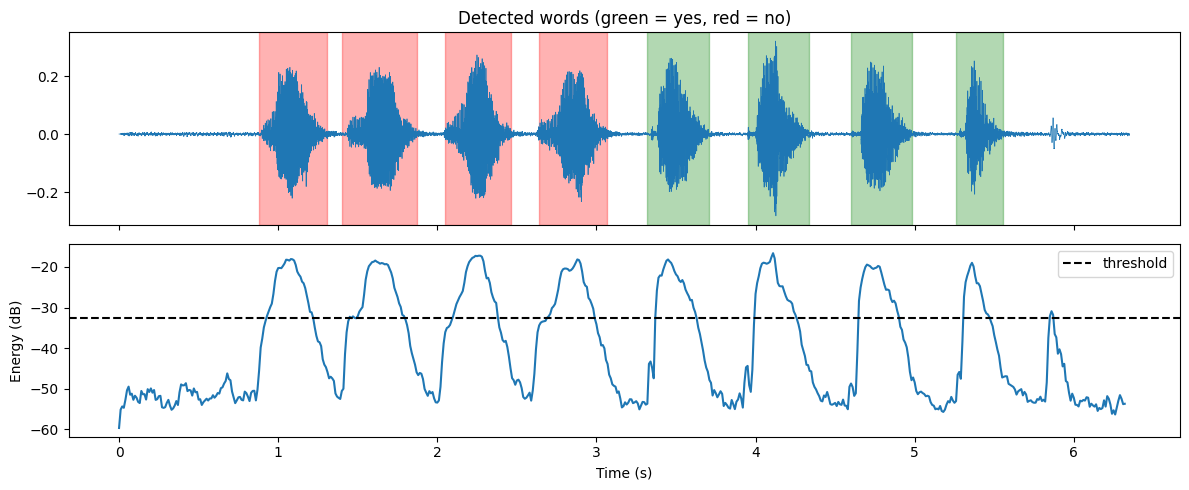

In [4]:
def frame_energy_db(x, frame=200, hop=80):
    # Split signal into overlapping frames and compute energy (dB) of each frame
    n = 1 + (len(x) - frame) // hop
    idx = np.arange(frame)[None, :] + hop * np.arange(n)[:, None]
    return 10 * np.log10(np.mean(x[idx] ** 2, axis=1) + 1e-10)

def find_segments(mask, min_gap, min_len):
    # Turn True/False frames into (start, end) segments
    segs, start = [], None
    for i, m in enumerate(mask):
        if m and start is None:
            start = i
        elif not m and start is not None:
            segs.append([start, i]); start = None
    if start is not None:
        segs.append([start, len(mask)])
    # Merge segments separated by a short gap
    merged = []
    for s, e in segs:
        if merged and s - merged[-1][1] < min_gap:
            merged[-1][1] = e
        else:
            merged.append([s, e])
    # Remove very short segments (clicks / noise)
    return [(s, e) for s, e in merged if e - s >= min_len]

def segment_words(x, sr, n_words=8, frame=200, hop=80, pad_s=0.05):
    energy = frame_energy_db(x, frame, hop)
    peak = np.percentile(energy, 99)                                   # speech peak level
    min_gap, min_len = int(0.15 * sr / hop), int(0.10 * sr / hop)      # 150 ms, 100 ms
    pad = int(pad_s * sr)
    # threshold = peak minus delta dB; try several deltas until we get exactly 8 words
    for delta in [15, 12, 18, 10, 20, 8, 25]:
        thr = peak - delta
        segs = find_segments(energy > thr, min_gap, min_len)
        if len(segs) == n_words:
            return [(max(0, s * hop - pad), min(len(x), e * hop + frame + pad)) for s, e in segs], energy, thr
    return None, energy, None

# Test on the first file
segs, energy, thr = segment_words(x, sr)
print("Found", len(segs), "words")

fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
ax[0].plot(t, x, linewidth=0.5)
for (s, e), lab in zip(segs, labels):
    ax[0].axvspan(s / sr, e / sr, color="green" if lab == 1 else "red", alpha=0.3)
ax[0].set_title("Detected words (green = yes, red = no)")
ft = np.arange(len(energy)) * 80 / sr
ax[1].plot(ft, energy); ax[1].axhline(thr, color="k", linestyle="--", label="threshold")
ax[1].set_ylabel("Energy (dB)"); ax[1].set_xlabel("Time (s)"); ax[1].legend()
plt.tight_layout(); plt.show()

*Figure 2: Detected words in a recording (green = yes, red = no) and the frame energy with the threshold.*

With this method 59 of the 60 recordings were split into exactly 8 words. One recording (0_1_0_1_0_0_0_0.wav) was excluded. The final dataset has 472 words, 249 yes and 223 no, with an average word length of 0.395 seconds.

Files segmented successfully: 59 / 60
Failed files: ['data/waves_yesno/0_1_0_1_0_0_0_0.wav']
Total words: 472 | yes: 249 | no: 223
Average word length (s): 0.395


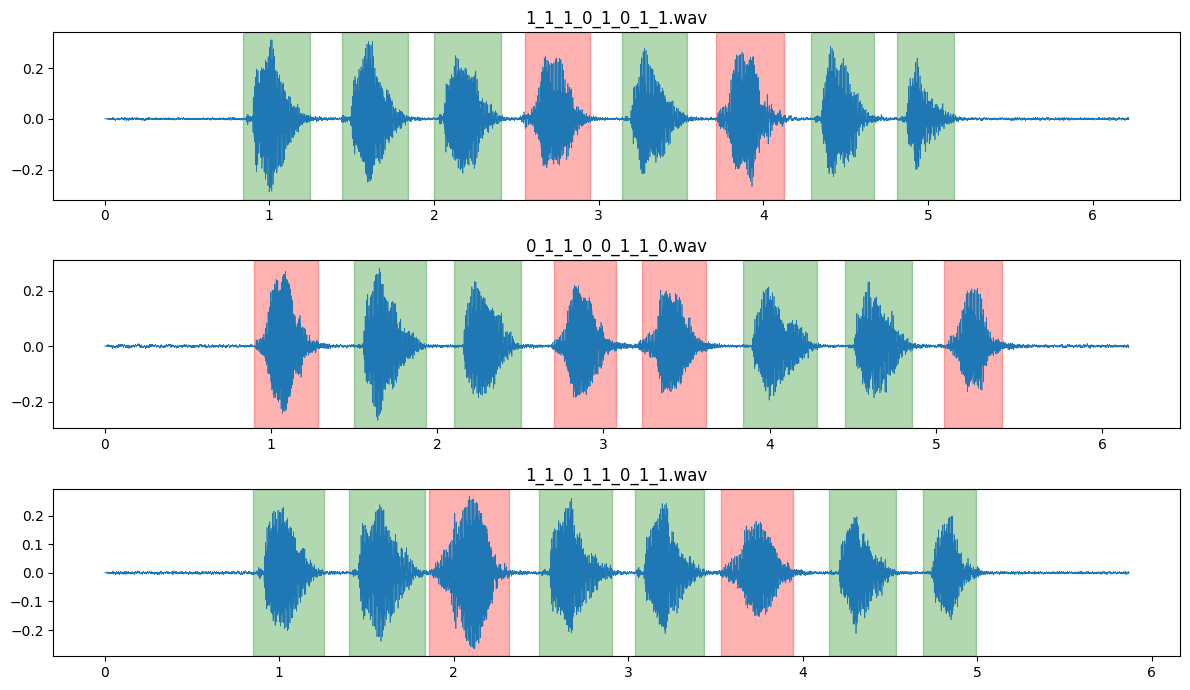

In [5]:
words, y, groups, failed = [], [], [], []

for file_id, f in enumerate(files):
    sig, sr = sf.read(f, dtype="float32")
    segs, _, _ = segment_words(sig, sr)
    if segs is None:
        failed.append(f)
        continue
    file_labels = [int(c) for c in os.path.basename(f)[:-4].split("_")]
    for (s, e), lab in zip(segs, file_labels):
        words.append(sig[s:e])     # the audio of one word
        y.append(lab)              # 0 = no, 1 = yes
        groups.append(file_id)     # which recording it came from

y, groups = np.array(y), np.array(groups)
print("Files segmented successfully:", len(files) - len(failed), "/", len(files))
print("Failed files:", failed)
print("Total words:", len(words), "| yes:", y.sum(), "| no:", len(y) - y.sum())
print("Average word length (s): %.3f" % np.mean([len(w) / sr for w in words]))

# Visual check on 3 random files
import random
random.seed(0)
fig, axes = plt.subplots(3, 1, figsize=(12, 7))
for ax, fid in zip(axes, random.sample(range(len(files)), 3)):
    sig, sr = sf.read(files[fid], dtype="float32")
    segs, _, _ = segment_words(sig, sr)
    lab = [int(c) for c in os.path.basename(files[fid])[:-4].split("_")]
    ax.plot(np.arange(len(sig)) / sr, sig, linewidth=0.5)
    if segs:
        for (s, e), l in zip(segs, lab):
            ax.axvspan(s / sr, e / sr, color="green" if l else "red", alpha=0.3)
    ax.set_title(os.path.basename(files[fid]))
plt.tight_layout(); plt.show()

### 3.2 Feature extraction
For each word, 13 MFCC coefficients were calculated using torchaudio (n_fft = 256, 40 Mel filters, 10 ms hop), together with their delta coefficients. Because the words have different lengths, the mean and standard deviation of each coefficient over time were taken. Adding the word duration gives a fixed feature vector of 53 values for every word.

Feature matrix X: (472, 53)
Labels y: (472,)


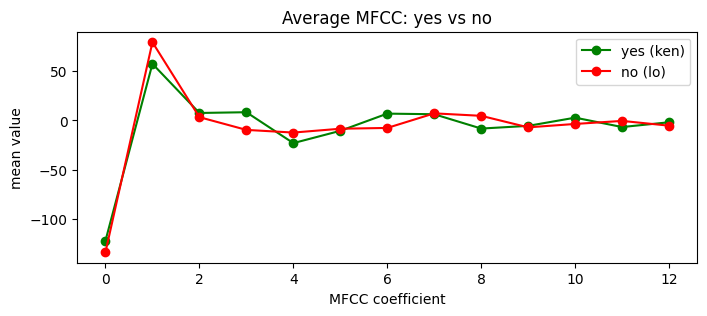

In [6]:
import torch, torchaudio

SR = 8000
mfcc_transform = torchaudio.transforms.MFCC(
    sample_rate=SR, n_mfcc=13,
    melkwargs=dict(n_fft=256, win_length=200, hop_length=80, n_mels=40))

def extract_features(w):
    m = mfcc_transform(torch.from_numpy(w).float().unsqueeze(0))[0]   # shape (13, T)
    d = torchaudio.functional.compute_deltas(m.unsqueeze(0))[0]        # shape (13, T)
    feats = torch.cat([m.mean(1), m.std(1),      # MFCC statistics
                       d.mean(1), d.std(1),      # delta statistics
                       torch.tensor([len(w) / SR])])  # word duration
    return feats.numpy()

X = np.stack([extract_features(w) for w in words])
print("Feature matrix X:", X.shape)   # expected (472, 53)
print("Labels y:", y.shape)

# Quick look: average MFCC of 'yes' vs 'no'
plt.figure(figsize=(8, 3))
plt.plot(X[y == 1, :13].mean(0), "g-o", label="yes (ken)")
plt.plot(X[y == 0, :13].mean(0), "r-o", label="no (lo)")
plt.xlabel("MFCC coefficient"); plt.ylabel("mean value"); plt.legend()
plt.title("Average MFCC: yes vs no"); plt.show()

*Figure 3: Average MFCC values for yes and no words.*

### 3.3 Train and test split
The data was split by recording and not by word. If the split were done randomly on words, words from the same recording would appear in both training and testing, and the results would be higher than they really are. Using GroupShuffleSplit, 41 recordings (328 words) were used for training and 18 recordings (144 words) for testing, with no recording shared between the two sets. In addition, 5-fold GroupKFold cross-validation was used to get a more reliable estimate.

In [7]:
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=SEED)
train_idx, test_idx = next(gss.split(X, y, groups))

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("Train:", len(train_idx), "words from", len(set(groups[train_idx])), "files")
print("Test: ", len(test_idx), "words from", len(set(groups[test_idx])), "files")
print("Shared files between train and test:", set(groups[train_idx]) & set(groups[test_idx]))

Train: 328 words from 41 files
Test:  144 words from 18 files
Shared files between train and test: set()


### 3.4 Classifiers
The following classifiers from scikit-learn were trained on the MFCC features. Features were standardised with StandardScaler for the models that depend on distances or scale.

1. Majority class baseline, used as a reference.
2. Logistic Regression.
3. k-Nearest Neighbours with k = 5.
4. Linear SVM.
5. SVM with RBF kernel (C = 10).
6. Decision Tree.
7. Random Forest with 300 trees.
8. Gaussian Naive Bayes.
9. Multi-layer Perceptron with one hidden layer of 64 neurons.

In [8]:
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

models = {
    "Majority baseline":   DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "k-NN (k=5)":          make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Linear SVM":          make_pipeline(StandardScaler(), SVC(kernel="linear")),
    "RBF SVM":             make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10)),
    "Decision Tree":       DecisionTreeClassifier(random_state=SEED),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=SEED),
    "Gaussian NB":         make_pipeline(StandardScaler(), GaussianNB()),
    "MLP (64)":            make_pipeline(StandardScaler(), MLPClassifier((64,), max_iter=2000, random_state=SEED)),
}

rows, preds = [], {}
gkf = GroupKFold(n_splits=5)

for name, model in models.items():
    # 1) train on train set, evaluate on held-out test files
    model.fit(X_train, y_train)
    p = model.predict(X_test)
    preds[name] = p
    # 2) 5-fold cross-validation grouped by recording
    cv = cross_val_score(model, X, y, groups=groups, cv=gkf, scoring="accuracy")
    rows.append({"Model": name,
                 "Test Acc": accuracy_score(y_test, p),
                 "Test F1": f1_score(y_test, p, average="macro"),
                 "CV Acc (mean)": cv.mean(),
                 "CV Acc (std)": cv.std()})
    print(f"{name:20s} | test acc = {rows[-1]['Test Acc']:.3f} | CV = {cv.mean():.3f} ± {cv.std():.3f}")

results = pd.DataFrame(rows)
results.round(4)

Majority baseline    | test acc = 0.500 | CV = 0.527 ± 0.028
Logistic Regression  | test acc = 1.000 | CV = 0.998 ± 0.004
k-NN (k=5)           | test acc = 0.993 | CV = 1.000 ± 0.000
Linear SVM           | test acc = 1.000 | CV = 1.000 ± 0.000
RBF SVM              | test acc = 0.993 | CV = 0.998 ± 0.004
Decision Tree        | test acc = 0.993 | CV = 0.987 ± 0.008
Random Forest        | test acc = 1.000 | CV = 1.000 ± 0.000
Gaussian NB          | test acc = 0.993 | CV = 0.998 ± 0.004
MLP (64)             | test acc = 0.993 | CV = 0.998 ± 0.004


,Model,Test Acc,Test F1,CV Acc (mean),CV Acc (std)
0,Majority baseline,0.5000,0.3333,0.5275,0.0283
1,Logistic Regression,1.0000,1.0000,0.9979,0.0042
2,k-NN (k=5),0.9931,0.9931,1.0000,0.0000
3,Linear SVM,1.0000,1.0000,1.0000,0.0000
4,RBF SVM,0.9931,0.9931,0.9979,0.0042
5,Decision Tree,0.9931,0.9931,0.9873,0.0078
6,Random Forest,1.0000,1.0000,1.0000,0.0000
7,Gaussian NB,0.9931,0.9931,0.9979,0.0042
8,MLP (64),0.9931,0.9931,0.9979,0.0042


### CNN (part of 3.4)
A convolutional neural network was also trained in PyTorch. Instead of MFCC statistics, its input is the log-Mel spectrogram of each word (40 Mel bands × 80 frames, padded or cropped to 0.8 s). The network has three convolution blocks with 16, 32 and 64 filters (each followed by batch normalisation, ReLU and pooling), global average pooling, dropout of 0.3 and a final linear layer with two outputs. It was trained for 40 epochs with the Adam optimiser (learning rate 0.001, batch size 32).

Spectrogram tensor: torch.Size([472, 1, 40, 80])


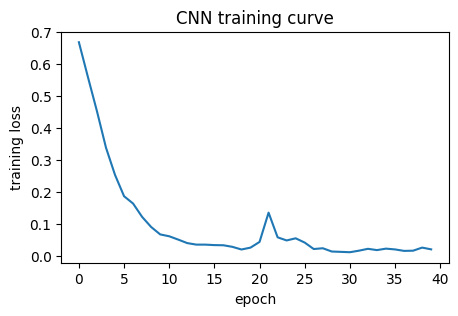

CNN | test acc = 0.924 | CV = 0.998 ± 0.004


,Model,Test Acc,Test F1,CV Acc (mean),CV Acc (std)
0,Majority baseline,0.5000,0.3333,0.5275,0.0283
1,Logistic Regression,1.0000,1.0000,0.9979,0.0042
2,k-NN (k=5),0.9931,0.9931,1.0000,0.0000
3,Linear SVM,1.0000,1.0000,1.0000,0.0000
4,RBF SVM,0.9931,0.9931,0.9979,0.0042
5,Decision Tree,0.9931,0.9931,0.9873,0.0078
6,Random Forest,1.0000,1.0000,1.0000,0.0000
7,Gaussian NB,0.9931,0.9931,0.9979,0.0042
8,MLP (64),0.9931,0.9931,0.9979,0.0042
9,CNN (log-Mel),0.9236,0.9232,0.9979,0.0042


In [10]:
import torch.nn as nn

torch.manual_seed(SEED)
mel = torchaudio.transforms.MelSpectrogram(sample_rate=SR, n_fft=256, win_length=200, hop_length=80, n_mels=40)
to_db = torchaudio.transforms.AmplitudeToDB()
T_FIX = 80   # fixed number of frames (0.8 s)

def logmel(w):
    s = to_db(mel(torch.from_numpy(w).float()))     # (40, T)
    T = s.shape[1]
    if T >= T_FIX:                                   # crop from the center
        st = (T - T_FIX) // 2
        s = s[:, st:st + T_FIX]
    else:                                            # pad both sides
        left = (T_FIX - T) // 2
        s = nn.functional.pad(s, (left, T_FIX - T - left), value=s.min().item())
    return s

S = torch.stack([logmel(w) for w in words]).unsqueeze(1)   # (N, 1, 40, 80)
S = (S - S[train_idx].mean()) / S[train_idx].std()          # normalize using train stats
Y = torch.tensor(y)
print("Spectrogram tensor:", S.shape)

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(64, 2))
    def forward(self, x):
        return self.net(x)

def train_cnn(tr, te, epochs=40, bs=32):
    torch.manual_seed(SEED)
    model = SmallCNN()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.CrossEntropyLoss()
    Xtr, Ytr = S[tr], Y[tr]
    losses = []
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr)); total = 0
        for i in range(0, len(Xtr), bs):
            b = perm[i:i + bs]
            opt.zero_grad()
            loss = loss_fn(model(Xtr[b]), Ytr[b])
            loss.backward(); opt.step()
            total += loss.item() * len(b)
        losses.append(total / len(Xtr))
    model.eval()
    with torch.no_grad():
        p = model(S[te]).argmax(1).numpy()
    return p, losses

# Train on train set, test on held-out files
p_cnn, losses = train_cnn(train_idx, test_idx)
plt.figure(figsize=(5, 3)); plt.plot(losses)
plt.xlabel("epoch"); plt.ylabel("training loss"); plt.title("CNN training curve"); plt.show()

# 5-fold group cross-validation
cv_cnn = []
for tr, te in gkf.split(X, y, groups):
    pc, _ = train_cnn(tr, te)
    cv_cnn.append(accuracy_score(y[te], pc))

preds["CNN (log-Mel)"] = p_cnn
results = pd.concat([results, pd.DataFrame([{
    "Model": "CNN (log-Mel)",
    "Test Acc": accuracy_score(y_test, p_cnn),
    "Test F1": f1_score(y_test, p_cnn, average="macro"),
    "CV Acc (mean)": np.mean(cv_cnn),
    "CV Acc (std)": np.std(cv_cnn)}])], ignore_index=True)

print(f"CNN | test acc = {accuracy_score(y_test, p_cnn):.3f} | CV = {np.mean(cv_cnn):.3f} ± {np.std(cv_cnn):.3f}")
results.round(4)

## 4. Results
Table 1 shows the results of all models on the test set and in cross-validation.

| Model | Test accuracy | Test F1 | CV accuracy (mean ± std) |
|---|:---:|:---:|:---:|
| Majority baseline | 0.500 | 0.333 | 0.527 ± 0.028 |
| Logistic Regression | 1.000 | 1.000 | 0.998 ± 0.004 |
| k-NN (k = 5) | 0.993 | 0.993 | 1.000 ± 0.000 |
| Linear SVM | 1.000 | 1.000 | 1.000 ± 0.000 |
| RBF SVM | 0.993 | 0.993 | 0.998 ± 0.004 |
| Decision Tree | 0.993 | 0.993 | 0.987 ± 0.008 |
| Random Forest | 1.000 | 1.000 | 1.000 ± 0.000 |
| Gaussian NB | 0.993 | 0.993 | 0.998 ± 0.004 |
| MLP (64) | 0.993 | 0.993 | 0.998 ± 0.004 |
| CNN (log-Mel) | 0.924 | 0.923 | 0.998 ± 0.004 |

*Table 1: Accuracy and F1 score of the classifiers (test set: 144 words from 18 recordings).*

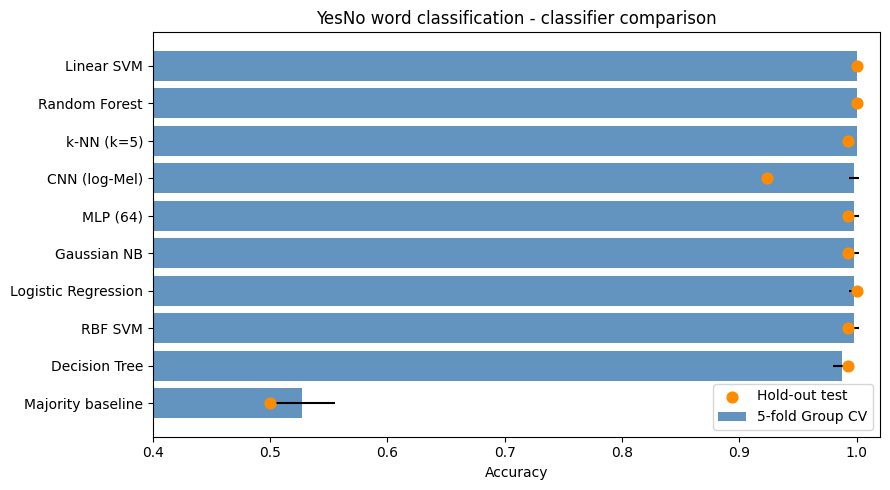

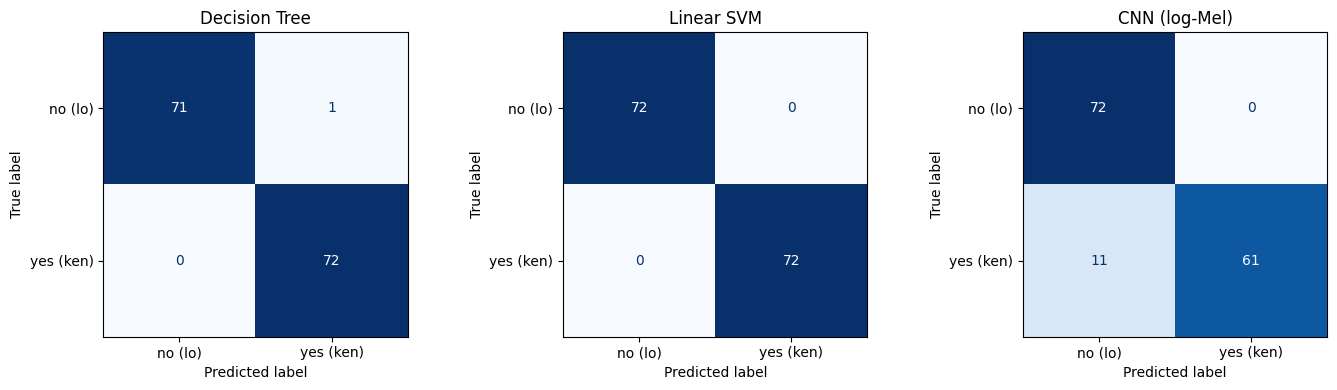

Best model: Linear SVM
              precision    recall  f1-score   support

          no       1.00      1.00      1.00        72
         yes       1.00      1.00      1.00        72

    accuracy                           1.00       144
   macro avg       1.00      1.00      1.00       144
weighted avg       1.00      1.00      1.00       144

Decision Tree   | recordings with all 8 words correct: 17/18
Linear SVM      | recordings with all 8 words correct: 18/18
CNN (log-Mel)   | recordings with all 8 words correct: 9/18


In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# 1) Bar chart comparison
r = results.sort_values("CV Acc (mean)")
plt.figure(figsize=(9, 5))
plt.barh(r["Model"], r["CV Acc (mean)"], xerr=r["CV Acc (std)"], color="steelblue", alpha=0.85, label="5-fold Group CV")
plt.scatter(r["Test Acc"], r["Model"], color="darkorange", zorder=3, s=60, label="Hold-out test")
plt.xlabel("Accuracy"); plt.xlim(0.4, 1.02); plt.legend(loc="lower right")
plt.title("YesNo word classification - classifier comparison")
plt.tight_layout(); plt.show()

# 2) Confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, ["Decision Tree", "Linear SVM", "CNN (log-Mel)"]):
    cm = confusion_matrix(y_test, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=["no (lo)", "yes (ken)"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.show()

# 3) Detailed report + recording-level accuracy for the best model
best = "Linear SVM"
print("Best model:", best)
print(classification_report(y_test, preds[best], target_names=["no", "yes"]))

g_test = groups[test_idx]
for name in ["Decision Tree", "Linear SVM", "CNN (log-Mel)"]:
    ok = [np.all(preds[name][g_test == g] == y_test[g_test == g]) for g in np.unique(g_test)]
    print(f"{name:15s} | recordings with all 8 words correct: {sum(ok)}/{len(ok)}")

*Figure 4: Comparison of the classifiers (bars: cross-validation accuracy, dots: test accuracy) — first plot above.*

The confusion matrices of three models were also examined, together with the number of test recordings in which all 8 words were classified correctly.

| Model | Errors (out of 144) | Type of errors | Correct recordings |
|---|:---:|:---:|:---:|
| Linear SVM | 0 | None | 18 / 18 |
| Decision Tree | 1 | One no predicted as yes | 17 / 18 |
| CNN (log-Mel) | 11 | All yes predicted as no | 9 / 18 |

*Table 2: Errors on the test set and recording-level accuracy.*

*Figure 5: Confusion matrices of the Decision Tree, Linear SVM and CNN — second plot above.*

## 5. Discussion
All the classic classifiers performed far better than the baseline, with accuracies between 98.7% and 100%. Linear SVM and Random Forest made no errors at all. The two words are very different acoustically: "ken" starts with the burst of /k/ followed by a front vowel, while "lo" starts with /l/ followed by a back vowel. This difference is captured well by the MFCC features, which explains why even linear models can separate the two classes perfectly.

The Decision Tree had the lowest cross-validation accuracy among the classic models (98.7%). A single tree splits the data on one feature at a time, which makes it less stable. Random Forest combines many trees and reached 100%.

The CNN reached 99.8% in cross-validation but only 92.4% on the hold-out test set, and all of its 11 errors were yes words predicted as no. The training loss decreased from about 0.7 to almost zero, with a small jump around epoch 20. The difference between the test and cross-validation results shows that the CNN is not stable with such a small amount of data (about 330 training words). No validation set or early stopping was used, so the final model depends on the split and on the epoch where training stopped. The CNN also needed about 4 minutes to train on CPU, while the classic models trained in a few seconds.

## 6. Conclusion
Different classifiers were trained on the YesNo dataset after cutting each recording into single words with an energy-based method. Using MFCC features, Linear SVM and Random Forest achieved 100% accuracy, and the other classic models were very close. The CNN worked but was less reliable on this small dataset, so a deep model is not needed for this task. The most difficult step was the segmentation of the words, not the classification. Splitting the data by recording was also important to get fair results.